In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_train.csv")
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [2]:
print(df.shape)


(60000, 785)


# Labels and its meaning



| Label | Description |
| :--- | :--- |
| 0 | T-shirt/top |
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |



# Viewing the dataset

Labels: [2, 9, 6, 0, 3, 4, 4, 5, 4, 8]


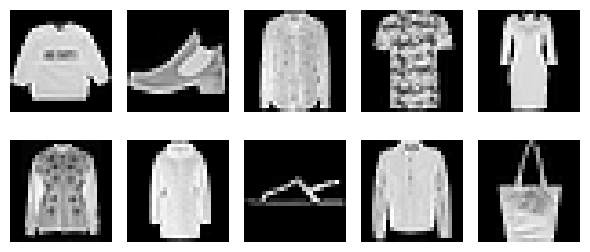

In [3]:
import matplotlib.pyplot as plt

labels = df["label"].head(10).to_list()
print(f"Labels: {labels}")

fig, axes = plt.subplots(2, 5, figsize=(6, 3))
axes = axes.flatten()

for i in range(10):
    img_raw = df.drop(columns=['label']).iloc[i].values
    img_shaped = img_raw.reshape(28,28)
    axes[i].imshow(img_shaped, cmap='gray')
    axes[i].axis("off")

plt.tight_layout()
plt.show()

# Check if test has labels

If it didnt, I'll have to use train and split a test there
However its not needed because theres labels in test.csv

In [4]:
df2 = pd.read_csv("/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_test.csv")
df2.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103,87,56,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,14,53,99,...,0,0,0,0,63,53,31,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,137,126,140,0,133,224,222,56,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


# Splitting the labels and creating the train test variables

In [5]:
train = df.copy() # Originally 60,000, 785
train_labels = train.pop("label") # removes the label column from the set
train = train.T # now 784, 60,000 where every column is an image

test = df2.copy() # Originally 10,000, 785
test_labels = test.pop("label") # removes the label column from the set
test = test.T # now 784, 10,000

In [6]:
print("TEST: ", test.shape)
print("TRAIN: ", train.shape)

TEST:  (784, 10000)
TRAIN:  (784, 60000)


# Normalizing the input, train and test
##### Very important step, I separated it so you can see it

In [7]:
test = test.astype(np.float64) / 255.0
train = train.astype(np.float64) / 255.0

# Initializing the weights and biases
##### Plus some overcomplicated kaiming init stuff

In [8]:
generate = np.random.default_rng(seed=67) # this is the generator of reproducible random numbers, funny number yes yes

def kaiming_init(Weights,activation_type, alpha= 0.01):
    activation_type = activation_type.lower().strip()
    n_in = Weights.shape[1]
    if activation_type == "relu":
        return Weights * np.sqrt(2/n_in)
    elif activation_type == "leaky_relu":
        return Weights * np.sqrt(2/((1+alpha**2) * n_in))
    else:
        raise ValueError("2nd parameter either: relu or leaky_relu")

# INPUT LAYER WEIGHTS AND BIAS
W1 = generate.standard_normal(size = (25, 784)) # 25 "neurons" by 784 columns
b1 = np.zeros((25, 1)) 

# LAYER 1
W2 = generate.standard_normal(size = (20,25)) # 20 "neurons" by 25 features from input neurons
b2 = np.zeros((20,1))

# LAYER 2
W3 = generate.standard_normal(size = (15, 20)) # 15 "neurons" by 20 features from previous layer
b3 = np.zeros((15,1))

# OUTPUT LAYER
W4 = generate.standard_normal(size = (10, 15)) # 10 output "neurons" from previous layer
b4 = np.zeros((10,1))

activation_type = "relu"
W1, W2, W3, W4 = [
                    kaiming_init(W, activation_type) 
                    for W in (W1, W2, W3, W4)
                 ]

# Yes yes, ik. I overcomplicated this part

# Helper Functions

In [9]:
def weightedSum(W, b, x):
    return W @ x + b

def relu(Z):
    return np.maximum(0, Z)

def softMax(Z):
    Z = np.asarray(Z) #safety net incase what was passed is a dataframe, not really neccesary if u know what ur doing, i just like keeping that there
    exp_Z = np.exp(Z - np.max(Z, axis=0, keepdims = True))
    return exp_Z / np.sum(exp_Z, axis=0, keepdims = True)


# Training Variables

In [13]:
epochs = 500
X = train.to_numpy()
Y = np.asarray(train_labels)
X_test = test.to_numpy()
Y_test = np.asarray(test_labels)
m = X.shape[1]

# Training Algorithm

In [14]:
learning_rate = 0.1
patience = 15
rate_decrease_times = 3
rate_decrease_count = 0
epochs_without_improvement = 0
best_validation_loss = float("inf")
best_weights_bias = None


for epoch in range(epochs):
    # 1. Forward pass using all training images.

    Z = weightedSum(W1, b1, X)
    A = relu(Z)
    Z2 = weightedSum(W2, b2, A)
    A2 = relu(Z2)
    Z3 = weightedSum(W3, b3, A2)
    A3 = relu(Z3)
    Z4 = weightedSum(W4, b4, A3)
    output = softMax(Z4)
    
    # 2. Backpropagation: calculate gradients, averaged over m.
    predicted_classes = np.asarray(np.argmax(output, axis = 0))
    correctly_predicted = (predicted_classes == Y)
    train_accuracy = np.mean(correctly_predicted)

    train_loss = -np.mean(
        np.log(np.clip(output[Y, np.arange(m)], 1e-12, 1.0))
    )


    """
    Each layer uses its own dZ to calculate its parameter gradients:
    dZ4 -> dW4, db4
    dZ3 -> dW3, db3
    dZ2 -> dW2, db2
    dZ  -> dW,  db
    """
    dZ4 = output.copy()
    dZ4[Y, np.arange(m)] -= 1
    dW4 = (dZ4 @ A3.T) / m
    db4 = np.sum(dZ4, axis = 1, keepdims=True) / m

    dZ3 = (W4.T @ dZ4) * (Z3 > 0) # Gradient of loss with respect to the neuron’s weighted sum before activation
                                  # Carries the loss’s effect backward through the network
    dW3 = (dZ3 @ A2.T) / m
    db3 = np.sum(dZ3, axis = 1, keepdims = True) / m

    dZ2 = (W3.T @ dZ3) * (Z2 > 0)
    dW2 = (dZ2 @ A.T) / m
    db2 = np.sum(dZ2, axis = 1, keepdims = True) / m

    dZ = (W2.T @ dZ2 ) * (Z > 0)
    dW = (dZ @ X.T) / m
    db = np.sum(dZ, axis = 1, keepdims = True) / m


       
    # 3. Update every weight and bias once.
    W1  -= learning_rate * dW
    b1  -= learning_rate * db
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W3 -= learning_rate * dW3
    b3 -= learning_rate * db3
    W4 -= learning_rate * dW4
    b4 -= learning_rate * db4


    
    # 4. Validate and run epoch controls.

    Z = weightedSum(W1, b1, X_test)
    A = relu(Z)
    Z2 = weightedSum(W2, b2, A)
    A2 = relu(Z2)
    Z3 = weightedSum(W3, b3, A2)
    A3 = relu(Z3)
    Z4 = weightedSum(W4, b4, A3)
    output = softMax(Z4)

    

    # Validation accuracy
    Y_test = np.asarray(Y_test)
    m_test = output.shape[1]
    
    predicted_classes = np.argmax(output, axis=0)
    eval_accuracy = np.mean(predicted_classes == Y_test)
    
    # Validation cross-entropy loss
    correct_probabilities = output[Y_test, np.arange(m_test)]
    eval_loss = -np.mean(
        np.log(np.clip(correct_probabilities, 1e-12, 1.0))
    )
    
    # Confusion matrix: rows = actual, columns = predicted
    num_classes = output.shape[0]
    confusion_matrix = np.zeros((num_classes, num_classes), dtype=int)
    
    for actual, predicted in zip(Y_test, predicted_classes):
        confusion_matrix[actual, predicted] += 1
    
    # Macro F1
    f1_per_class = []
    
    for digit in range(num_classes):
        TP = confusion_matrix[digit, digit]
        FP = confusion_matrix[:, digit].sum() - TP
        FN = confusion_matrix[digit, :].sum() - TP
    
        denominator = 2 * TP + FP + FN
        f1 = 2 * TP / denominator if denominator > 0 else 0.0
        f1_per_class.append(f1)
    
    macro_f1 = np.mean(f1_per_class)
    
    print(
        f"Epoch {epoch + 1} | "
        f"Train accuracy: {train_accuracy:.2%} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation accuracy: {eval_accuracy:.2%} | "
        f"Validation loss: {eval_loss:.4f} | "
        f"Macro F1: {macro_f1:.3f}"
    )


    if eval_loss < best_validation_loss: # If the new eval loss is LESSER than the old one, then copy the weights and biases
        best_weights_bias = [
            W1.copy(), b1.copy(),
            W2.copy(), b2.copy(),
            W3.copy(), b3.copy(),
            W4.copy(), b4.copy()
        ]# copy weights and biases
        best_validation_loss = eval_loss # get the best validation loss 
        epochs_without_improvement = 0
    else: # If no improvements in the loss, then add 1 in the epochs without improvement
        epochs_without_improvement +=1

    if epochs_without_improvement >= patience: # If algorithm loses patience then decrease learning rate, add to rate decrease count and reset epoch improv count
        if rate_decrease_count < rate_decrease_times:
            rate_decrease_count +=1
            learning_rate *= 0.1 #Decrease learning rate by one decimal place
            epochs_without_improvement = 0
        else:
            break 
    
if best_weights_bias is not None:
    W1, b1, W2, b2, W3, b3, W4, b4 = [
        parameter.copy() for parameter in best_weights_bias
    ]
    


Epoch 1 | Train accuracy: 72.50% | Train loss: 0.7540 | Validation accuracy: 68.93% | Validation loss: 0.7768 | Macro F1: 0.654
Epoch 2 | Train accuracy: 69.59% | Train loss: 0.7652 | Validation accuracy: 71.10% | Validation loss: 0.7665 | Macro F1: 0.676
Epoch 3 | Train accuracy: 71.57% | Train loss: 0.7561 | Validation accuracy: 68.68% | Validation loss: 0.7955 | Macro F1: 0.646
Epoch 4 | Train accuracy: 69.11% | Train loss: 0.7832 | Validation accuracy: 70.50% | Validation loss: 0.7800 | Macro F1: 0.663
Epoch 5 | Train accuracy: 70.99% | Train loss: 0.7693 | Validation accuracy: 68.49% | Validation loss: 0.8120 | Macro F1: 0.642
Epoch 6 | Train accuracy: 68.68% | Train loss: 0.7993 | Validation accuracy: 70.18% | Validation loss: 0.7940 | Macro F1: 0.659
Epoch 7 | Train accuracy: 70.69% | Train loss: 0.7829 | Validation accuracy: 68.83% | Validation loss: 0.7982 | Macro F1: 0.648
Epoch 8 | Train accuracy: 68.99% | Train loss: 0.7855 | Validation accuracy: 70.21% | Validation loss: 0

In [15]:
# ========================== SETTINGS ==========================

learning_rate = 0.1
epochs = 100
train_batch_size = 100
validation_batch_size = 300

patience = 15
rate_decrease_times = 3
rate_decrease_count = 0
epochs_without_improvement = 0

best_validation_loss = float("inf")
best_weights_bias = None
best_epoch = None
best_metrics = None

shuffle_rng = np.random.default_rng(seed=42)

X = np.asarray(X)
Y = np.asarray(Y)
X_test = np.asarray(X_test)
Y_test = np.asarray(Y_test)

train_size = X.shape[1]
validation_size = X_test.shape[1]


# ========================== TRAINING ==========================

for epoch in range(epochs):
    # Shuffle image positions. Use the SAME positions for labels.
    order = shuffle_rng.permutation(train_size)

    train_correct = 0
    train_count = 0
    train_loss_sum = 0.0

    for start in range(0, train_size, train_batch_size):
        indices = order[start:start + train_batch_size]

        X_batch = X[:, indices]
        Y_batch = Y[indices]
        m = X_batch.shape[1]

        # -------------------- Forward pass --------------------

        Z1 = weightedSum(W1, b1, X_batch)
        A1 = relu(Z1)

        Z2 = weightedSum(W2, b2, A1)
        A2 = relu(Z2)

        Z3 = weightedSum(W3, b3, A2)
        A3 = relu(Z3)

        Z4 = weightedSum(W4, b4, A3)
        output = softMax(Z4)

        # -------------------- Training metrics --------------------

        predicted = np.argmax(output, axis=0)

        train_correct += np.sum(predicted == Y_batch)
        train_count += m

        correct_probabilities = output[Y_batch, np.arange(m)]
        train_loss_sum += -np.log(
            np.clip(correct_probabilities, 1e-12, 1.0)
        ).sum()

        # -------------------- Backpropagation --------------------

        dZ4 = output.copy()
        dZ4[Y_batch, np.arange(m)] -= 1
        dW4 = (dZ4 @ A3.T) / m
        db4 = np.sum(dZ4, axis=1, keepdims=True) / m

        dZ3 = (W4.T @ dZ4) * (Z3 > 0)
        dW3 = (dZ3 @ A2.T) / m
        db3 = np.sum(dZ3, axis=1, keepdims=True) / m

        dZ2 = (W3.T @ dZ3) * (Z2 > 0)
        dW2 = (dZ2 @ A1.T) / m
        db2 = np.sum(dZ2, axis=1, keepdims=True) / m

        dZ1 = (W2.T @ dZ2) * (Z1 > 0)
        dW1 = (dZ1 @ X_batch.T) / m
        db1 = np.sum(dZ1, axis=1, keepdims=True) / m

        # -------------------- One update per batch --------------------

        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1

        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

        W3 -= learning_rate * dW3
        b3 -= learning_rate * db3

        W4 -= learning_rate * dW4
        b4 -= learning_rate * db4

    # Whole-epoch training metrics.
    train_accuracy = train_correct / train_count
    train_loss = train_loss_sum / train_count

    # ========================== VALIDATION ==========================

    eval_correct = 0
    eval_count = 0
    eval_loss_sum = 0.0

    num_classes = W4.shape[0]
    confusion_matrix = np.zeros(
        (num_classes, num_classes), dtype=int
    )

    for start in range(0, validation_size, validation_batch_size):
        X_val = X_test[:, start:start + validation_batch_size]
        Y_val = Y_test[start:start + validation_batch_size]
        m_val = X_val.shape[1]

        # Forward pass only. Weights stay fixed.
        Z1_val = weightedSum(W1, b1, X_val)
        A1_val = relu(Z1_val)

        Z2_val = weightedSum(W2, b2, A1_val)
        A2_val = relu(Z2_val)

        Z3_val = weightedSum(W3, b3, A2_val)
        A3_val = relu(Z3_val)

        Z4_val = weightedSum(W4, b4, A3_val)
        output_val = softMax(Z4_val)

        # Accumulate results across validation batches.
        predicted_val = np.argmax(output_val, axis=0)

        eval_correct += np.sum(predicted_val == Y_val)
        eval_count += m_val

        correct_probabilities = output_val[Y_val, np.arange(m_val)]
        eval_loss_sum += -np.log(
            np.clip(correct_probabilities, 1e-12, 1.0)
        ).sum()

        for actual, predicted in zip(Y_val, predicted_val):
            confusion_matrix[actual, predicted] += 1

    # Whole-validation-set metrics.
    eval_accuracy = eval_correct / eval_count
    eval_loss = eval_loss_sum / eval_count

    f1_per_class = []

    for class_index in range(num_classes):
        TP = confusion_matrix[class_index, class_index]
        FP = confusion_matrix[:, class_index].sum() - TP
        FN = confusion_matrix[class_index, :].sum() - TP

        denominator = 2 * TP + FP + FN
        f1 = 2 * TP / denominator if denominator > 0 else 0.0
        f1_per_class.append(f1)

    macro_f1 = np.mean(f1_per_class)

    print(
        f"Epoch {epoch + 1} | "
        f"LR: {learning_rate:.3e} | "
        f"Train accuracy: {train_accuracy:.2%} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation accuracy: {eval_accuracy:.2%} | "
        f"Validation loss: {eval_loss:.4f} | "
        f"Macro F1: {macro_f1:.3f}"
    )

    # ========================== EPOCH CONTROLS ==========================

    if eval_loss < best_validation_loss:
        best_validation_loss = eval_loss
        best_epoch = epoch + 1

        best_weights_bias = [
            W1.copy(), b1.copy(),
            W2.copy(), b2.copy(),
            W3.copy(), b3.copy(),
            W4.copy(), b4.copy()
        ]

        best_metrics = {
            "validation_accuracy": eval_accuracy,
            "validation_loss": eval_loss,
            "macro_f1": macro_f1
        }

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        if rate_decrease_count < rate_decrease_times:
            learning_rate *= 0.1
            rate_decrease_count += 1
            epochs_without_improvement = 0

            print(f"Learning rate reduced to {learning_rate:.3e}")

        else:
            print("Early stopping: patience exhausted.")
            break


# ========================== RESTORE BEST MODEL ==========================

if best_weights_bias is not None:
    W1, b1, W2, b2, W3, b3, W4, b4 = [
        parameter.copy() for parameter in best_weights_bias
    ]

    print(
        f"\nRestored epoch {best_epoch} | "
        f"Validation loss: {best_metrics['validation_loss']:.4f} | "
        f"Validation accuracy: "
        f"{best_metrics['validation_accuracy']:.2%} | "
        f"Macro F1: {best_metrics['macro_f1']:.3f}"
    )

Epoch 1 | LR: 1.000e-01 | Train accuracy: 79.49% | Train loss: 0.5667 | Validation accuracy: 80.37% | Validation loss: 0.5219 | Macro F1: 0.793
Epoch 2 | LR: 1.000e-01 | Train accuracy: 83.13% | Train loss: 0.4596 | Validation accuracy: 84.06% | Validation loss: 0.4455 | Macro F1: 0.835
Epoch 3 | LR: 1.000e-01 | Train accuracy: 84.25% | Train loss: 0.4263 | Validation accuracy: 83.90% | Validation loss: 0.4334 | Macro F1: 0.839
Epoch 4 | LR: 1.000e-01 | Train accuracy: 85.27% | Train loss: 0.3997 | Validation accuracy: 86.49% | Validation loss: 0.3817 | Macro F1: 0.865
Epoch 5 | LR: 1.000e-01 | Train accuracy: 85.76% | Train loss: 0.3841 | Validation accuracy: 86.25% | Validation loss: 0.3838 | Macro F1: 0.862
Epoch 6 | LR: 1.000e-01 | Train accuracy: 86.26% | Train loss: 0.3695 | Validation accuracy: 85.86% | Validation loss: 0.3811 | Macro F1: 0.861
Epoch 7 | LR: 1.000e-01 | Train accuracy: 86.73% | Train loss: 0.3611 | Validation accuracy: 86.68% | Validation loss: 0.3725 | Macro F1